# DBD plasma diagnostics — step-by-step tutorial / 단계별 튜토리얼

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MJ-best/ms-thesis-dbd-plasma-diagnostics/blob/main/notebooks/tutorial.ipynb)

This notebook walks through every computation of the M.S. thesis *Electrical measurements and prediction of dielectric barrier surface damage in nonthermal atmospheric pressure DBD plasma based on machine learning* (M. Kim, Kwangwoon Univ., 2023) using the `dbd_diagnostics` package.
이 노트북은 학위논문의 계산 과정을 `dbd_diagnostics` 패키지로 한 단계씩 따라갑니다.

The raw thesis data are not public, so the notebook uses **synthetic waveforms from the equivalent-circuit simulator**; with your own oscilloscope CSV files, replace the simulator call by `io.load_csv(...)`.
원본 측정 데이터는 공개하지 않았으므로 **등가회로 시뮬레이터로 만든 합성 파형**을 사용합니다. 직접 측정한 CSV가 있으면 `io.load_csv(...)`로 바꾸면 됩니다.

| Step | Content |
|---|---|
| 1 | Waveform: V–I capture, integer periods / 파형과 주기 |
| 2 | V_rms, I_rms, energy per cycle, power / 실효값·에너지·전력 |
| 3 | Lissajous figure and equivalent circuit / 리사주와 등가회로 |
| 4 | Burning voltage vs. thesis Eq. (15) / 방전 유지 전압과 논문 식 (15) |
| 5 | Discharge pulses / 방전 펄스 |
| 6 | E/N, electron temperature and density / 환산전기장·전자온도·전자밀도 |
| 7 | Feature table and machine learning across devices / 특성표와 장치 간 머신러닝 |

In [1]:
# Install the package when running on Colab / Colab에서 실행할 때 패키지 설치
import importlib.util, subprocess, sys
if importlib.util.find_spec("dbd_diagnostics") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "git+https://github.com/MJ-best/ms-thesis-dbd-plasma-diagnostics"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dbd_diagnostics import simulate, waveform, electrical, lissajous, discharge, plasma, features, ml

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 4)

## 1. Waveform / 파형

The thesis device is a coplanar micro-gap surface DBD (126 cell pairs, 100 µm gap) driven at ≈46.5 kHz, ≈2.2 kV peak. `simulate.cells` builds the same situation from the equivalent circuit: each cell fires a micro-discharge when its gap voltage exceeds its breakdown threshold, and the result is passed through an emulated measurement chain (60 MHz current probe, 100 MS/s, 8-bit ADC), like the GW Instek GDS-2102A captures of the thesis.

논문 장치(126쌍 셀, 100 µm 갭, 46.5 kHz)를 등가회로로 흉내 낸 합성 파형입니다. 각 셀은 갭 전압이 문턱값을 넘으면 미세방전을 일으키고, 결과는 실제 측정 체인(60 MHz 전류 프로브, 100 MS/s, 8-bit)을 거친 것처럼 만들어집니다.

samples: 4947, dt = 10 ns, one period = 2150 samples, f = 46.51 kHz


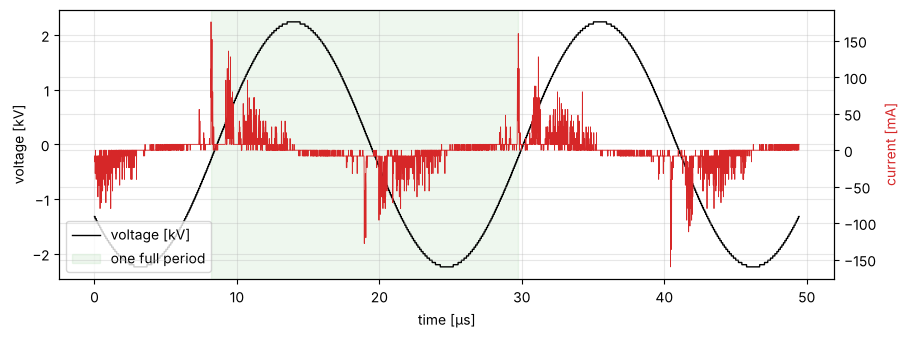

In [2]:
p = simulate.CircuitParams(C_d=34.2e-12, C_g=16.9e-12, U_b=900.0, V_amp=2240.0, f=46.5e3)
wf = simulate.cells(p, seed=0, periods=2.3)           # one "oscilloscope capture"
# wf = io.load_csv("ALL0001.CSV")                      # <- your own capture

win = waveform.one_period_window(wf.t, wf.v)           # rising zero crossing -> next one
t, v, i = wf.t[win.slice], wf.v[win.slice], wf.i[win.slice]
v = v - v.mean()
print(f"samples: {len(wf)}, dt = {wf.dt*1e9:.0f} ns, one period = {len(t)} samples, f = {win.frequency/1e3:.2f} kHz")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(wf.t * 1e6, wf.v / 1e3, "k", lw=1, label="voltage [kV]")
ax.axvspan(t[0] * 1e6, t[-1] * 1e6, color="tab:green", alpha=0.08, label="one full period")
ax2 = ax.twinx(); ax2.plot(wf.t * 1e6, wf.i * 1e3, "tab:red", lw=0.6); ax2.set_ylabel("current [mA]", color="tab:red")
ax.set_xlabel("time [µs]"); ax.set_ylabel("voltage [kV]"); ax.legend(loc="lower left"); plt.show()

## 2. RMS, energy per cycle, power / 실효값·1주기 에너지·전력

* $V_{rms}=\sqrt{\frac1T\int_0^T v^2dt}$, $I_{rms}=\sqrt{\frac1T\int_0^T i^2dt}$ (thesis Eqs. 9–10)
* **Energy per cycle** $E=\int_0^T v\,i\,dt$ [J] — the thesis' "0.13 mJ" is this quantity (not per second)
* **Mean power** $P = E f$ [W] (≈ 6 W for the thesis device)

The current must be offset-free before any integration: with 8 mA/LSB, a one-LSB offset integrates to ≈170 nC per period (3× the discharge charge).
전류 오프셋은 반드시 제거해야 합니다(1 LSB = 8 mA의 오프셋이 주기당 약 170 nC로 누적).

In [3]:
i0 = electrical.remove_offset(t, i)
print(f"current offset removed : {np.mean(i)*1e3:+.2f} mA")
print(f"V_rms = {electrical.rms(t, v):.0f} V,  I_rms = {electrical.rms(t, i0)*1e3:.1f} mA")
E = electrical.energy_per_cycle(t, v, i0)
print(f"energy per cycle E = {E*1e3:.4f} mJ  ->  mean power P = E*f = {E*win.frequency:.2f} W")
T = t[-1] - t[0]
print(f"charge drift per period caused by this offset   : {np.mean(i)*T*1e9:.1f} nC")
print(f"... and by a one-LSB offset of 8 mA (thesis scope): {8e-3*T*1e9:.0f} nC  (vs. ~60 nC discharge charge)")

current offset removed : +0.14 mA
V_rms = 1585 V,  I_rms = 18.7 mA
energy per cycle E = 0.1069 mJ  ->  mean power P = E*f = 4.97 W
charge drift per period caused by this offset   : 3.0 nC
... and by a one-LSB offset of 8 mA (thesis scope): 172 nC  (vs. ~60 nC discharge charge)


## 3. Lissajous figure and equivalent circuit / 리사주 그래프와 등가회로

Equivalent circuit (Manley 1943): dielectric capacitance $C_d$ in series with the gas gap $C_g$; while the gap conducts its voltage is clamped at the **burning voltage** $U_b$.

* no discharge: slope $dQ/dV = C_{total} = C_dC_g/(C_d+C_g)$ (thesis Eq. 24)
* discharge: $Q = C_d (V - U_b)$ → slope $C_{dielectric}$

`lissajous.analyse` splits the period at the voltage extrema and fits each branch with two straight lines (optimal breakpoint = discharge onset).

C_total = 12.50 pF,  C_dielectric = 34.28 pF,  C_gas = 19.67 pF
fit R^2: C_total 0.988,  C_dielectric 0.991
transferred charge per half cycle (thesis Q_max) = 83.8 nC
burning voltage U_b: onset method 598 V, energy method 637 V (126 cells that fire between 0.4 and 1.0 x 900 V -> effective ~630 V)


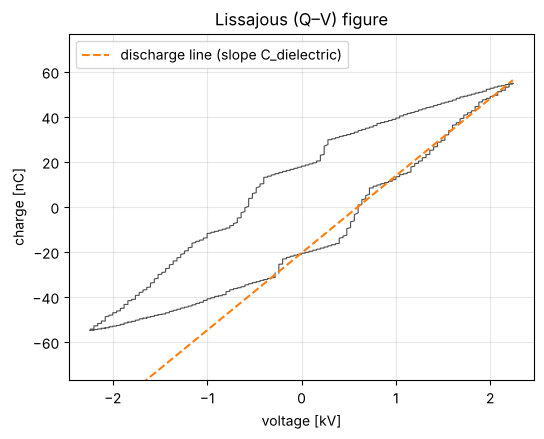

In [4]:
q = electrical.charge(t, i0)                     # running integral, centred
L = lissajous.analyse(t, v, q)
print(f"C_total = {L.C_total*1e12:.2f} pF,  C_dielectric = {L.C_dielectric*1e12:.2f} pF,  C_gas = {L.C_gas*1e12:.2f} pF")
print(f"fit R^2: C_total {L.fit_total[0].r2:.3f},  C_dielectric {L.fit_dielectric[0].r2:.3f}")
print(f"transferred charge per half cycle (thesis Q_max) = {L.dQ*1e9:.1f} nC")
print(f"burning voltage U_b: onset method {L.U_b_onset:.0f} V, energy method {L.U_b_energy:.0f} V "
      f"(126 cells that fire between 0.4 and 1.0 x 900 V -> effective ~630 V)")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(v / 1e3, q * 1e9, color="0.3", lw=0.8)
vv = np.linspace(-L.V_max, L.V_max, 50)
ax.plot(vv / 1e3, L.C_dielectric * (vv - L.U_b) * 1e9, "--", color="tab:orange", label="discharge line (slope C_dielectric)")
ax.set_xlabel("voltage [kV]"); ax.set_ylabel("charge [nC]"); ax.set_ylim(-1.4 * abs(q).max() * 1e9, 1.4 * abs(q).max() * 1e9)
ax.legend(loc="upper left"); ax.set_title("Lissajous (Q–V) figure"); plt.show()

## 4. Burning voltage vs. thesis Eq. (15) / 방전 유지 전압과 논문 식 (15)

The thesis computed $V_{breakdown}=V_{min}+Q_{max}/C_{dielectric}$. Because the discharge-phase slope *is* $C_{dielectric}$, $Q_{max}=C_{dielectric}(V_{max}-V_{min})$ and the formula returns **$V_{max}$**, the peak applied voltage.
The gas voltage follows from $u_g(t)=v(t)-Q(t)/C_d$ and

$$U_b = V_{on}-\frac{Q_{on}}{C_d}=\Big(1-\frac{C_{total}}{C_d}\Big)\frac{V_{max}+V_{on}}{2}=\frac{E}{2\Delta Q}.$$

The ideal model has a known answer ($U_b$ = 900 V), so we can check every estimator.
이상적인 등가회로는 정답(U_b = 900 V)을 알고 있으므로 각 계산식을 직접 확인할 수 있습니다.

,voltage [V]
true U_b (model input),900.0
U_b = V_on - Q_on/C_d,900.0
U_b = (1-C_t/C_d)(V_max+V_on)/2,900.0
U_b = E/(2 dQ),900.0
U_b = V-intercept of discharge line,900.0
thesis Eq.15 V_min + Q_max/C_d,2240.0
peak applied voltage V_max,2240.0
"Paschen, 100 µm air, gamma=0.01",865.0


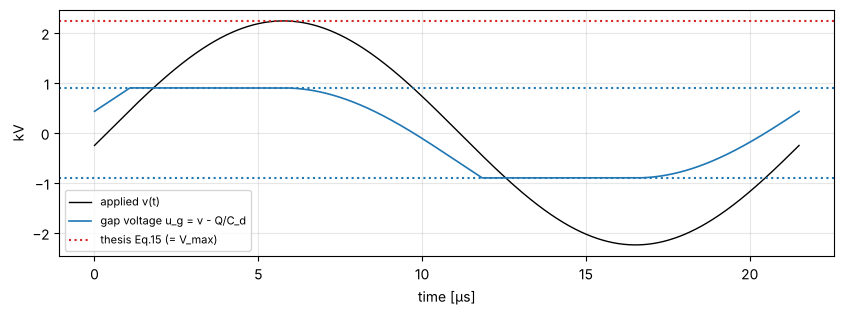

In [5]:
wi = simulate.ideal(p)
w = waveform.one_period_window(wi.t, wi.v)
ti, vi, ii = wi.t[w.slice], wi.v[w.slice], wi.i[w.slice]
qi = electrical.charge(ti, electrical.remove_offset(ti, ii))
Li = lissajous.analyse(ti, vi, qi)
rows = {"true U_b (model input)": p.U_b,
        "U_b = V_on - Q_on/C_d": Li.U_b_onset,
        "U_b = (1-C_t/C_d)(V_max+V_on)/2": Li.U_b_geometry,
        "U_b = E/(2 dQ)": Li.U_b_energy,
        "U_b = V-intercept of discharge line": Li.U_b_intercept,
        "thesis Eq.15  V_min + Q_max/C_d": Li.V_breakdown_thesis,
        "peak applied voltage V_max": Li.V_max,
        "Paschen, 100 µm air, gamma=0.01": plasma.paschen_voltage(760, 0.01)}
display(pd.DataFrame({"voltage [V]": rows}).round(0))

ug = lissajous.gap_voltage(vi, qi, Li.C_dielectric)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot((ti - ti[0]) * 1e6, vi / 1e3, "k", lw=1, label="applied v(t)")
ax.plot((ti - ti[0]) * 1e6, ug / 1e3, "tab:blue", lw=1.2, label="gap voltage u_g = v - Q/C_d")
for s in (1, -1): ax.axhline(s * Li.U_b / 1e3, color="tab:blue", ls=":")
ax.axhline(Li.V_breakdown_thesis / 1e3, color="tab:red", ls=":", label="thesis Eq.15 (= V_max)")
ax.set_xlabel("time [µs]"); ax.set_ylabel("kV"); ax.legend(loc="lower left", fontsize=8); plt.show()

## 5. Discharge pulses / 방전 펄스

* `thesis` detector: two-pass `find_peaks` with threshold = median prominence × 1.5 and IQR width filtering (the original algorithm, with its slice-index bug fixed).
* `robust` detector: peaks of the displacement-free **discharge current** $i_{dis}=(i-C_{total}\,dv/dt)/(1-C_{total}/C_d)$ above 5 × MAD noise.

Pulses are counted from the zero crossing to the voltage extremum of each half cycle. With 10 ns sampling the counts are lower bounds.

robust : 14.0 pulses / half cycle, onset |V| = 320 V
thesis : 44.0 pulses / half cycle, onset |V| = 460 V


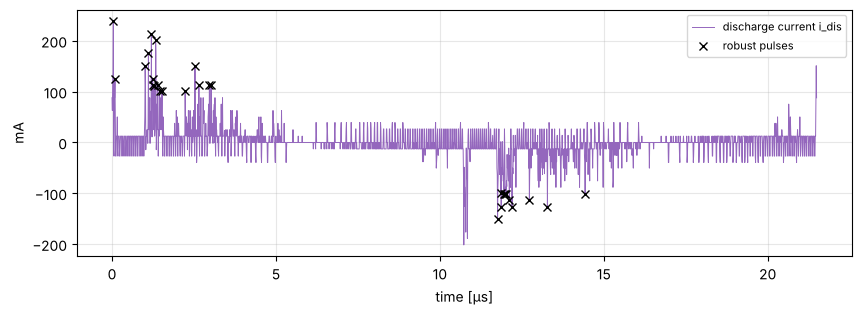

In [6]:
i_dis = lissajous.discharge_current(t, v, i0, L.C_dielectric, L.C_total)
ps_r = discharge.pulse_statistics(v, i_dis, method="robust")
ps_t = discharge.pulse_statistics(v, i0, method="thesis")
print(f"robust : {ps_r.n_discharges:.1f} pulses / half cycle, onset |V| = {ps_r.v_onset:.0f} V")
print(f"thesis : {ps_t.n_discharges:.1f} pulses / half cycle, onset |V| = {ps_t.v_onset:.0f} V")

fig, ax = plt.subplots(figsize=(10, 3.2))
tt = (t - t[0]) * 1e6
ax.plot(tt, i_dis * 1e3, color="tab:purple", lw=0.7, label="discharge current i_dis")
ax.plot(tt[ps_r.peak_indices], i_dis[ps_r.peak_indices] * 1e3, "x", color="k", label="robust pulses")
ax.set_xlabel("time [µs]"); ax.set_ylabel("mA"); ax.legend(fontsize=8); plt.show()

## 6. E/N, electron temperature and density / 환산전기장·전자온도·전자밀도

* $N=p/(k_BT)$ = 2.50×10¹⁹ cm⁻³ at 20 °C (the thesis used 2.8×10¹⁹)
* $E/N = U/(dN)$, 1 Td = 10⁻¹⁷ V cm²
* $k_BT_e/e = D_e/\mu_e(E/N)$, table digitised from thesis Fig. 15 (source data to 175 Td, Raizer's curve ends near 300 Td; beyond that the table is the thesis' extrapolation)
* $n_e = i\,d/(\mu_e e A U)$ with $\mu_e$ = 592 cm²/Vs, $A$ = 4.5×10⁻⁴ cm²

The thesis used $V_{breakdown}\approx V_{max}$, which puts $E/N$ at ≈800 Td, outside the table (extrapolated T_e ≈ 13 eV). With the burning voltage the operating point (≈ 340 Td) lies just beyond the end of Raizer's curve, a short extrapolation (T_e ≈ 6 eV).

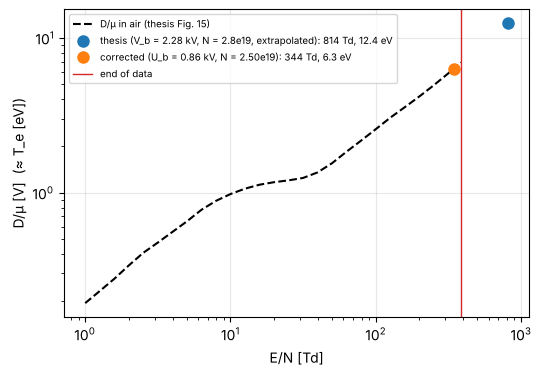

n_e with i = 14.3 mA: 1.60e+12 cm^-3 (thesis V_b = 2.1 kV)  ->  3.90e+12 cm^-3 (U_b = 0.86 kV)


In [7]:
d, N = 0.01, plasma.number_density()
en, dmu = plasma.dmu_table()
cases = {"thesis (V_b = 2.28 kV, N = 2.8e19, extrapolated)": (2278.6, 2.8e19, True),
         "corrected (U_b = 0.86 kV, N = 2.50e19)": (860.0, N, False)}
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(en / 1e-17, dmu, "k--", label="D/μ in air (thesis Fig. 15)")
for name, (U, n_, ex) in cases.items():
    x = plasma.reduced_field(U, d, n_) / 1e-17
    te = plasma.electron_temperature_from_field(U, d, n_, extrapolate=ex)
    ax.plot(x, te, "o", ms=8, label=f"{name}: {x:.0f} Td, {te:.1f} eV")
ax.axvline(en.max() / 1e-17, color="tab:red", lw=1, label="end of data")
ax.set_xlabel("E/N [Td]"); ax.set_ylabel("D/μ [V]  (≈ T_e [eV])"); ax.legend(fontsize=7); plt.show()

ne_thesis = plasma.electron_density(0.0143, d, 4.5e-4, 2100, plasma.electron_mobility())
print(f"n_e with i = 14.3 mA: {ne_thesis:.2e} cm^-3 (thesis V_b = 2.1 kV)  ->  "
      f"{plasma.electron_density(0.0143, d, 4.5e-4, 860, plasma.electron_mobility()):.2e} cm^-3 (U_b = 0.86 kV)")

## 7. Feature table and machine learning across devices / 특성표와 장치 간 머신러닝

`features.extract` returns the 14 thesis features plus corrected ones for one capture. Below we build an **illustrative synthetic aging dataset**: two devices whose damaged state is modelled as a small sag of the applied voltage, a larger effective dielectric capacitance and a lower burning voltage, with device-to-device offsets. *The numbers are illustrative, not the thesis results* (see `docs/thesis-review.md`, section H, for the re-analysis of the real data).

아래는 **예시용 합성 열화 데이터**입니다. 손상 상태를 인가전압 감소, 유효 유전체 커패시턴스 증가, 방전 유지 전압 감소로 모델링하고 장치 간 차이를 넣었습니다. 실제 논문 데이터의 재분석 결과는 검증 보고서 H절에 있습니다.

In [8]:
rng = np.random.default_rng(1)
rows = []
# device B is built slightly differently: lower supply output and a larger effective C_d,
# i.e. its *healthy* state already looks a bit like a damaged device A
for dev, (dV, dC) in {"A": (0.0, 0.0), "B": (-120.0, 2.5e-12)}.items():
    for label in (0, 1):
        for k in range(12):
            sag, dCd, dUb = ((0.0, 0.0, 0.0) if label == 0 else (0.06, 0.08, 0.06))
            pp = simulate.CircuitParams(
                C_d=(34.2e-12 + dC) * (1 + dCd) * (1 + 0.02 * rng.standard_normal()),
                C_g=16.9e-12 * (1 + 0.02 * rng.standard_normal()),
                U_b=900 * (1 - dUb) * (1 + 0.02 * rng.standard_normal()),
                V_amp=(2240 + dV) * (1 - sag) * (1 + 0.005 * rng.standard_normal()), f=46.5e3)
            r = features.extract(simulate.cells(pp, seed=int(rng.integers(1e9)), periods=2.3))
            r.update(device=dev, label=label); rows.append(r)
df = pd.DataFrame(rows)
df[["device", "label", "v_rms", "i_rms", "energy", "c_dielectric", "c_total", "q_max", "u_b", "v_breakdown", "te", "te_corrected", "n_discharges"]].groupby(["device", "label"]).mean()

v_rms   i_rms  energy  c_dielectric     c_total       q_max  \
device label                                                                    
A      0      1583.5470  0.0186  0.0001    3.3534e-11  1.2569e-11  8.1960e-08   
       1      1491.2377  0.0194  0.0001    3.6178e-11  1.2818e-11  8.6552e-08   
B      0      1494.1353  0.0194  0.0001    3.6798e-11  1.3002e-11  8.2363e-08   
       1      1407.7921  0.0200  0.0001    4.0131e-11  1.3298e-11  8.5202e-08   

                   u_b  v_breakdown       te  te_corrected  n_discharges  
device label                                                              
A      0      602.5884    2465.7253  13.2229        4.7809       11.5833  
       1      563.5873    2285.0329  12.4512        4.5519       11.2917  
B      0      582.5978    2257.9501  12.3343        4.6638       14.4583  
       1      535.4397    2158.3355  11.9024        4.3845       15.7500

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
models = {k: m for k, m in ml.thesis_models().items() if k in ("LR", "RF", "SVM", "kNN")}
models["RF"].set_params(clf__n_estimators=300)
feats = ml.THESIS_FEATURES
res = []
A = df[df.device == "A"]
tr, te = train_test_split(A, test_size=0.25, stratify=A.label, random_state=0)
for name, m in models.items():
    est = clone(m).fit(tr[feats], tr.label)
    res.append({"setting": "random split within device A", "model": name,
                **ml.evaluate(te.label, est.predict(te[feats]), ml.scores(est, te[feats]))})
for r in ml.group_holdout(df, feats, "label", "device", models):
    res.append({"setting": f"train {r.train_groups[0]} -> test {r.test_groups[0]}", "model": r.model, **r.metrics})
ref = pd.Series(np.zeros(len(df), bool), index=df.index)
for dev in df.device.unique():                                  # first 4 healthy captures per device = baseline
    ref[df.index[(df.device == dev) & (df.label == 0)][:4]] = True
dn = ml.baseline_normalize(df, feats, "device", ref)
for r in ml.group_holdout(dn, feats, "label", "device", models):
    res.append({"setting": f"baseline-normalised, test {r.test_groups[0]}", "model": r.model, **r.metrics})
R = pd.DataFrame(res)
display(R.pivot_table(index="setting", columns="model", values="accuracy").round(3))
R.pivot_table(index="setting", columns="model", values="auc").round(3)

model,LR,RF,SVM,kNN
setting,,,,
"baseline-normalised, test A",1.0,1.000,1.0,0.958
"baseline-normalised, test B",1.0,0.958,1.0,1.000
random split within device A,1.0,1.000,1.0,1.000
train A -> test B,0.5,0.500,0.5,0.500
train B -> test A,0.5,0.500,0.5,0.500


model,LR,RF,SVM,kNN
setting,,,,
"baseline-normalised, test A",1.0,1.000,1.0,0.990
"baseline-normalised, test B",1.0,1.000,1.0,1.000
random split within device A,1.0,1.000,1.0,1.000
train A -> test B,1.0,0.785,1.0,0.542
train B -> test A,1.0,0.885,1.0,0.500


**Reading the table / 해석**

* A random split inside one device is optimistic — neighbouring captures are almost identical.
* Training on one device and testing on the other is the honest setting; device-to-device offsets shift the decision threshold, so accuracy drops while the AUC (ranking) can stay high — exactly what the thesis saw for LR/SVM on its validation device (AUC 0.99, accuracy 76 %).
* Normalising each feature by the device's own early, known-healthy captures removes most of that offset.

같은 장치 안의 무작위 분할은 낙관적입니다. 장치 간 검증이 실제 상황에 맞는 평가이며, 장치별 기준값 정규화로 장치 간 차이를 줄일 수 있습니다.

## Next steps / 다음 단계

* Your own data: `dbd-diag extract <folder> -o features.csv`, add `device` and `label` columns, then `ml.group_holdout(...)`.
* Methods: [`docs/methods.md`](https://github.com/MJ-best/ms-thesis-dbd-plasma-diagnostics/blob/main/docs/methods.md) · verification report: [`docs/thesis-review.md`](https://github.com/MJ-best/ms-thesis-dbd-plasma-diagnostics/blob/main/docs/thesis-review.md)
* Please cite: M. Kim, M.S. thesis, Kwangwoon University (2023), https://www.dbpia.co.kr/journal/detail?nodeId=T16940279